# Data quality check

Before making any plots or running any tests, we check the processed files here. Questions 1 and 3 rely on `data/processed/efoi_2025.csv`, the sample that includes reply timestamps, while Question 2 uses `data/processed/frame_2025.csv` because every listing in the frame already has a status. The notebook only prints counts and summaries, so it never shows titles, purposes, tracking numbers, or source URLs.

In [1]:
from pathlib import Path
import sys

import pandas as pd

ROOT = Path("..")
sys.path.insert(0, str(ROOT / "scripts"))
from analysis import GROUP_ORDER

QUARTER_ORDER = ["Q1", "Q2", "Q3", "Q4"]

sample = pd.read_csv(ROOT / "data/processed/efoi_2025.csv", parse_dates=["filed_at"])
frame = pd.read_csv(ROOT / "data/processed/frame_2025.csv", parse_dates=["filed_at"])
sample["first_response_days"] = pd.to_numeric(sample["first_response_days"], errors="coerce")
sample["is_final"] = sample["is_final"].astype("boolean")

print(f"Sample: {len(sample):,} requests with reply timelines")
print(f"Frame:  {len(frame):,} public requests filed in 2025")

Sample: 1,641 requests with reply timelines
Frame:  14,668 public requests filed in 2025


## Missing first responses

`first_response_days` is blank whenever the agency never posted a message. We leave those rows blank rather than filling them with zero, since a zero would wrongly suggest that the agency answered instantly.

In [2]:
missing = sample["first_response_days"].isna()
replies_before_filing = int(sample["flag_reply_before_filing"].astype("boolean").sum())

print(f"{int(missing.sum()):,} of {len(sample):,} sampled requests have no first response")
print(f"Replies dated before filing: {replies_before_filing}")

by_outcome = (
    sample.loc[missing, "outcome"].value_counts().rename("no reply")
)
by_group = (
    sample.loc[missing, "agency_group"].value_counts().reindex(GROUP_ORDER).rename("no reply")
)
display(by_outcome.to_frame())
display(by_group.to_frame())

205 of 1,641 sampled requests have no first response
Replies dated before filing: 0


,no reply
outcome,
open,149
referred,34
unsuccessful,22


,no reply
agency_group,
NGA,17
GOCC,40
SUC,41
WATER-DISTRICT,75
LGU,30
LEA,2


## Open and closed requests

Question 2 uses every request in the frame, with open and referred requests kept as their own categories instead of being counted as unsuccessful. Question 3 is limited to closed requests, meaning those with `is_final` set: successful, partially successful, denied, or closed. Because that test also needs a first-response time, a closed request with no agency message can't be included, and the counts below show how many requests that affects. Notebook 03 then checks whether leaving them out changes the answer.

In [3]:
print("Sample")
display(sample["outcome"].value_counts().rename("requests").to_frame())
closed = sample["is_final"]
closed_no_reply = closed & missing
print(f"Closed: {int(closed.sum()):,}")
print(f"  with a first response (these go into the Question 3 test): {int((closed & ~missing).sum()):,}")
print(f"  with no first response: {int(closed_no_reply.sum()):,}")
print(f"Not closed: {int((~closed).sum()):,}")

print("Frame")
display(frame["outcome"].value_counts().rename("requests").to_frame())
open_or_referred = frame["outcome"].isin(["open", "referred"]).sum()
print(f"Open or referred in the frame: {int(open_or_referred):,}")

Sample


,requests
outcome,
successful,871
unsuccessful,441
open,198
partially successful,97
referred,34


Closed: 1,409
  with a first response (these go into the Question 3 test): 1,387
  with no first response: 22
Not closed: 232
Frame


,requests
outcome,
successful,7111
unsuccessful,3801
partially successful,2057
open,1024
referred,675


Open or referred in the frame: 1,699


## Agency groups

We drew up to 300 requests from each agency group, but the frame itself is far from balanced, since most requests go to national government agencies. A plain average over the sample would therefore give the smaller groups too much weight, which is why population estimates use `sampling_weight`.

In [4]:
counts = pd.DataFrame({
    "frame": frame["agency_group"].value_counts(),
    "sample": sample["agency_group"].value_counts(),
}).reindex(GROUP_ORDER)
counts["frame_share"] = counts["frame"] / counts["frame"].sum()
counts["sample_share"] = counts["sample"] / counts["sample"].sum()
display(counts.round({"frame_share": 3, "sample_share": 3}))

,frame,sample,frame_share,sample_share
agency_group,,,,
NGA,12219,298,0.833,0.182
GOCC,1284,300,0.088,0.183
SUC,344,301,0.023,0.183
WATER-DISTRICT,287,287,0.020,0.175
LGU,175,175,0.012,0.107
LEA,359,280,0.024,0.171


## Shape of response times, and the filing gap

Question 1 compares `first_response_days` across agency groups. The usual way to compare several groups is one-way ANOVA, but it assumes the values within each group are roughly normal, and when they aren't, the course guide recommends the non-parametric alternative, Kruskal–Wallis, which compares ranks instead of means. To see which case we're in, we check normality in three steps: first the summary below, where a mean far above the median together with a large skew points to a long right tail; then a Shapiro–Wilk test within each agency group; and finally a Q-Q plot, which shows where the data departs from a normal curve.

The same cell also lists any long gaps between filing dates. The portal has no public requests from 20 March to 18 June 2025, so comparisons between quarters need to keep that gap in mind.

In [5]:
replied = sample.loc[~missing, "first_response_days"]
summary = replied.describe(percentiles=[0.25, 0.5, 0.75, 0.95])
display(summary.to_frame("first_response_days"))
print(f"Skew: {replied.skew():.2f}")
print(f"Under 1 day: {(replied < 1).mean():.1%}")
print(f"Over 15 days: {(replied > 15).mean():.1%}")

dates = pd.Series(frame["filed_at"].dt.normalize().unique()).sort_values().reset_index(drop=True)
gap_days = dates.diff().dt.days
long_gaps = gap_days[gap_days > 7]

print("Filing gaps longer than 7 days:")
if long_gaps.empty:
    print("  none")
for i, days in long_gaps.items():
    print(f"  {dates.iloc[i - 1].date()} to {dates.iloc[i].date()} ({int(days)} days)")

quarters = pd.DataFrame({
    "frame": frame["filing_quarter"].value_counts(),
    "sample": sample["filing_quarter"].value_counts(),
}).reindex(QUARTER_ORDER)
display(quarters)

,first_response_days
count,1436.000000
mean,17.441636
std,52.774926
min,0.001000
25%,0.533000
50%,1.584500
75%,6.047750
95%,108.042000
max,527.031000


Skew: 4.82
Under 1 day: 42.2%
Over 15 days: 15.3%
Filing gaps longer than 7 days:
  2025-03-20 to 2025-06-18 (90 days)


,frame,sample
filing_quarter,,
Q1,4701,467
Q2,324,64
Q3,4902,597
Q4,4741,513


### Shapiro–Wilk test by agency group

Shapiro–Wilk tests whether a sample could plausibly come from a normal distribution, and a p-value below 0.05 means we reject normality for that group. We run it within each group because ANOVA assumes normality inside the groups rather than in the pooled data. Response times are right-skewed, and a log transform often fixes that, so the table tests both the raw and the logged values; if the logged values passed, ANOVA on log days would be an option. Only requests with a reply are tested, since a missing time has nothing to test.

In [6]:
import numpy as np
from scipy.stats import shapiro

rows = []
for group in GROUP_ORDER:
    days = sample.loc[(sample["agency_group"] == group) & ~missing, "first_response_days"]
    raw = shapiro(days)
    logged = shapiro(np.log(days))
    rows.append({
        "agency_group": group,
        "n": len(days),
        "W_raw": raw.statistic,
        "p_raw": raw.pvalue,
        "W_log": logged.statistic,
        "p_log": logged.pvalue,
    })
normality = pd.DataFrame(rows).set_index("agency_group")
shown = normality.copy()
for column in ("W_raw", "W_log"):
    shown[column] = shown[column].round(3)
for column in ("p_raw", "p_log"):
    shown[column] = shown[column].map(lambda value: f"{value:.2g}")
display(shown)

raw_fails = int((normality["p_raw"] < 0.05).sum())
log_fails = int((normality["p_log"] < 0.05).sum())
print(f"Raw days: normality rejected in {raw_fails} of {len(normality)} groups")
print(f"Log days: normality rejected in {log_fails} of {len(normality)} groups")

,n,W_raw,p_raw,W_log,p_log
agency_group,,,,,
NGA,281,0.312,4.4e-31,0.982,0.0013
GOCC,260,0.414,3e-28,0.969,2e-05
SUC,260,0.497,1.5e-26,0.963,3.3e-06
WATER-DISTRICT,212,0.394,3.8e-26,0.965,4.3e-05
LGU,145,0.570,7.6e-19,0.968,0.0019
LEA,278,0.215,1.6e-32,0.954,1.1e-07


Raw days: normality rejected in 6 of 6 groups
Log days: normality rejected in 6 of 6 groups


A perfectly normal sample would have W = 1, and the raw values fall far below that, which fits the skew we saw earlier: most replies arrive within a day or two, while a few take months. The log values come much closer to normal but still fail the test, so a log transform doesn't rescue ANOVA. The Q-Q plot shows the same thing by placing each response time against where it would fall if the data were normal, so points sitting on the line indicate normal data.

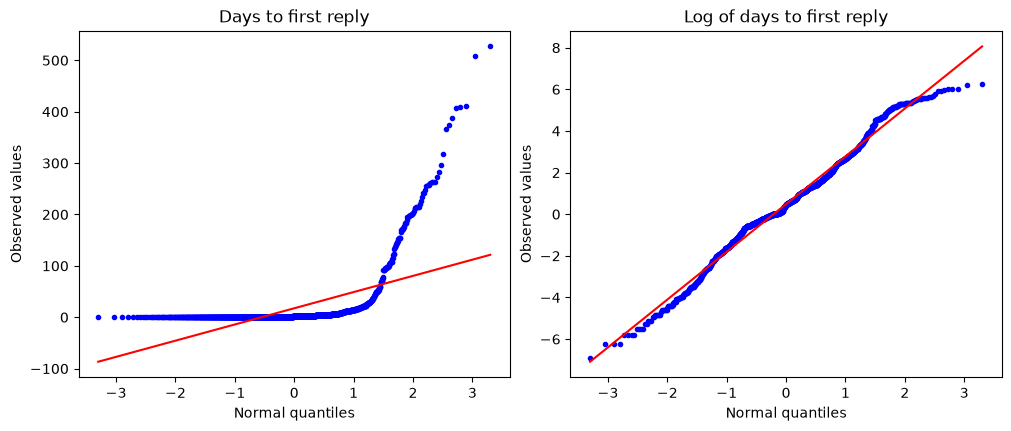

In [7]:
import matplotlib.pyplot as plt
from scipy.stats import probplot

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), constrained_layout=True)
probplot(replied, dist="norm", plot=axes[0])
axes[0].set_title("Days to first reply")
probplot(np.log(replied), dist="norm", plot=axes[1])
axes[1].set_title("Log of days to first reply")
for ax in axes:
    ax.set_xlabel("Normal quantiles")
    ax.set_ylabel("Observed values")
    ax.get_lines()[0].set_markersize(3)
plt.show()

On the left, the points curve sharply upward at the right end, which means the slowest replies are far slower than a normal distribution would allow. On the right, the log values follow the line through the middle but bend away at both ends, and that is why Shapiro–Wilk still rejects them.

## Sampled pages that were no longer public

We drew 1,663 requests, but 22 of their detail pages had disappeared from the portal by the time we collected, so they aren't in the dataset. If those pages were a random slice, we would lose only a little precision, so the check below compares them with the rest of their strata, using the drawn sample (`data/interim/sample.csv`) because it still has a listing status for every drawn request. Since those strata now hold fewer rows than we drew, the stored `sampling_weight` (population ÷ number drawn) adds up to less than the frame, and notebooks 02 and 03 therefore recompute the weight from the number actually collected (`collected_weights` in `scripts/analysis.py`).

In [8]:
import sys
from analysis import collected_weights

drawn = pd.read_csv(ROOT / "data/interim/sample.csv")
lost = drawn.loc[~drawn["tracking_number"].isin(sample["tracking_number"])]
print(f"Drawn: {len(drawn):,}. Collected: {len(sample):,}. Lost: {len(lost)}")
display(lost.groupby(["agency_group", "filing_quarter"]).size().rename("lost").to_frame())

lea_q1 = frame.loc[(frame["agency_group"] == "LEA") & (frame["filing_quarter"] == "Q1")]
comparison = pd.DataFrame({
    "lost pages": lost["outcome"].value_counts(normalize=True),
    "all LEA Q1 requests (frame)": lea_q1["outcome"].value_counts(normalize=True),
}).fillna(0).mul(100).round(1)
display(comparison)

print(f"Stored weights sum to {sample['sampling_weight'].sum():,.0f}; the frame has {len(frame):,} requests.")
print(f"Weights from the collected count sum to {collected_weights(sample).sum():,.0f}.")


Drawn: 1,663. Collected: 1,641. Lost: 22


,,lost
agency_group,filing_quarter,
LEA,Q1,20
NGA,Q1,2


,lost pages,all LEA Q1 requests (frame)
outcome,,
open,9.1,1.6
partially successful,0.0,1.6
successful,13.6,55.6
unsuccessful,77.3,41.1


Stored weights sum to 14,563; the frame has 14,668 requests.
Weights from the collected count sum to 14,668.


## What the checks decide

In [9]:
print(f"{int(missing.sum()):,} sampled requests have no first response. Leave first_response_days missing.")
print(
    f"Question 3 has {int(closed.sum()):,} closed requests. {int((closed & ~missing).sum()):,} have a first "
    f"response and go into the test; the other {int(closed_no_reply.sum()):,} are checked separately in notebook 03."
)
print("Question 2 uses every request in the frame. Open and referred stay their own outcomes.")
print("Population estimates use sampling_weight. The sample over-represents the smaller agency groups.")
print(
    "Question 1 uses Kruskal-Wallis, not ANOVA: "
    f"skew {replied.skew():.2f}, median {replied.median():.1f} days, mean {replied.mean():.1f} days, "
    f"and Shapiro-Wilk rejects normality in {raw_fails} of {len(normality)} groups "
    f"({log_fails} of {len(normality)} after a log transform)."
)
if long_gaps.empty:
    print("No filing gap longer than 7 days.")
else:
    spans = [
        f"{dates.iloc[i - 1].date()} to {dates.iloc[i].date()}"
        for i in long_gaps.index
    ]
    print("Quarter comparisons have to account for the filing gap: " + "; ".join(spans) + ".")

205 sampled requests have no first response. Leave first_response_days missing.
Question 3 has 1,409 closed requests. 1,387 have a first response and go into the test; the other 22 are checked separately in notebook 03.
Question 2 uses every request in the frame. Open and referred stay their own outcomes.
Population estimates use sampling_weight. The sample over-represents the smaller agency groups.
Question 1 uses Kruskal-Wallis, not ANOVA: skew 4.82, median 1.6 days, mean 17.4 days, and Shapiro-Wilk rejects normality in 6 of 6 groups (6 of 6 after a log transform).
Quarter comparisons have to account for the filing gap: 2025-03-20 to 2025-06-18.
